# UPI Spending Analysis

## Project Overview

This project analyses six months of personal UPI transaction data from January to June 2026 extracted from a Google Pay transaction statement

The workflow covers PDF- based transaction extraction, data cleaning, feature engineering, transaction categorisation and exploratory data analysis.

### Tools
Python · Pandas · Matplotlib · pdfplumber

### Analytical Focus
- Spending trends over time
- Category and merchant- level expenditure
- Transaction behaviour 
- Paid vs Received money flow
- Spending concentration
- Data quality and categorisation challenges

## Objectives

- Compare money paid and received
- Analyse monthly spending patterns
- Identify major spending categories
- Identify top merchants by total spending
- Analyse transaction frequency and average transaction value
- Analyse weekday vs weekend spending
- Examine spending concentration across merchants/categories
- Identify top 10% concentration analysis


1. IMPORT LIBRARIES

In [1]:
import pdfplumber
import pandas as pd
import re
import matplotlib.pyplot as plt

2. DATA EXTRACTION

In [2]:
pdf_path="/home/paragchengappa/programming/UPI-Spending-Analyser/data/raw/bankstats.pdf"

text=""

with pdfplumber.open(pdf_path) as pdf:
    for page in pdf.pages:
        page_text=page.extract_text()
        if page_text:
            text+=page_text+"\n"

print(text[:3000])

Transaction statement
9019517497, paragchengappa@gmail.com
Transactionstatementperiod Sent Received
01January2026-30June2026 ₹77,368.99 ₹70,536
Date&time Transactiondetails Amount
03Jan,2026 PaidtoJAYARAMAPB ₹30
07:41AM UPITransactionID:600358945338
PaidbyStateBankofIndia7202
03Jan,2026 PaidtoSHIVANNA SHIVANNA ₹231
02:17PM UPITransactionID:636962750553
PaidbyStateBankofIndia7202
05Jan,2026 PaidtoPARASHURAMA ₹56.15
07:29AM UPITransactionID:600553332781
PaidbyStateBankofIndia7202
05Jan,2026 PaidtoRAMESHMR ₹5
09:45AM UPITransactionID:600558105853
PaidbyStateBankofIndia7202
05Jan,2026 ReceivedfromMC NALINAKSHI ₹1,100
01:14PM UPITransactionID:969952655934
PaidtoStateBankofIndia7202
05Jan,2026 ReceivedfromMC NALINAKSHI ₹300
01:19PM UPITransactionID:527376183990
PaidtoStateBankofIndia7202
05Jan,2026 PaidtoBlinkit ₹1,112
01:19PM UPITransactionID:637121529011
PaidbyStateBankofIndia7202
06Jan,2026 PaidtoBMTCBUSKA57F1114 ₹15
12:03PM UPITransactionID:600608819250
PaidbyStateBankofIndia7202
Note:Th

In [3]:
transactions=[]

In [4]:
lines = text.splitlines()

In [5]:
import re
i=0

while i<len(lines):
    line=lines[i]

    if re.match(r"\d{2}[A-Za-z]{3},\d{4}",line):

        line1=lines[i]
        line2=lines[i+1]
        line3=lines[i+2]

        date=re.search(r"\d{2}[A-Za-z]{3},\d{4}",line1).group()

        amount=re.search(r"₹[\d,\.]+",line1).group()

        details=line1.replace(date,"")
        details=details.replace(amount,"").strip()

        time=re.search(r"\d{2}:\d{2}[AP]M",line2).group()

        upi=re.search(r"\d{12}",line2).group()
        bank=line3

        transactions.append([date,time,details,amount,upi,bank])

        i+=3

    else:
        i+=1


In [6]:
df=pd.DataFrame(transactions,columns=["Date","Time","Details","Amount","UPI_ID","Bank"])
df.head(10)

,Date,Time,Details,Amount,UPI_ID,Bank
0,"03Jan,2026",07:41AM,PaidtoJAYARAMAPB,₹30,600358945338,PaidbyStateBankofIndia7202
1,"03Jan,2026",02:17PM,PaidtoSHIVANNA SHIVANNA,₹231,636962750553,PaidbyStateBankofIndia7202
2,"05Jan,2026",07:29AM,PaidtoPARASHURAMA,₹56.15,600553332781,PaidbyStateBankofIndia7202
3,"05Jan,2026",09:45AM,PaidtoRAMESHMR,₹5,600558105853,PaidbyStateBankofIndia7202
4,"05Jan,2026",01:14PM,ReceivedfromMC NALINAKSHI,"₹1,100",969952655934,PaidtoStateBankofIndia7202
5,"05Jan,2026",01:19PM,ReceivedfromMC NALINAKSHI,₹300,527376183990,PaidtoStateBankofIndia7202
6,"05Jan,2026",01:19PM,PaidtoBlinkit,"₹1,112",637121529011,PaidbyStateBankofIndia7202
7,"06Jan,2026",12:03PM,PaidtoBMTCBUSKA57F1114,₹15,600608819250,PaidbyStateBankofIndia7202
8,"08Jan,2026",11:31AM,PaidtoSmartBazaar BengaluruFR47,₹22.50,600811739250,PaidbyStateBankofIndia7202
9,"08Jan,2026",11:38AM,PaidtoKA01AR2969,₹15,600812237069,PaidbyStateBankofIndia7202


3. DATA CLEANING

The extracted transaction data was cleaned and standardised before analysis


In [7]:
df["Date"]=pd.to_datetime(df["Date"],format="%d%b,%Y")

In [8]:
df["Amount"]=(df["Amount"]
              .str.replace("₹","",regex=False)
              .str.replace(",","",regex=False)
              .astype(float)
)

In [9]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 513 entries, 0 to 512
Data columns (total 6 columns):
 #   Column   Non-Null Count  Dtype         
---  ------   --------------  -----         
 0   Date     513 non-null    datetime64[ns]
 1   Time     513 non-null    object        
 2   Details  513 non-null    object        
 3   Amount   513 non-null    float64       
 4   UPI_ID   513 non-null    object        
 5   Bank     513 non-null    object        
dtypes: datetime64[ns](1), float64(1), object(4)
memory usage: 24.2+ KB


In [10]:
df.isnull().sum()

Date       0
Time       0
Details    0
Amount     0
UPI_ID     0
Bank       0
dtype: int64

In [11]:
df.duplicated().sum()

0

### Data Quality
The extracted dataset contains 513 transactions with no missing values and no duplicate rows

4. FEATURE ENGINEERING

In [12]:
df["Transaction_Type"]=df["Details"].apply(
    lambda x:"Paid" if x.startswith("Paid") else "Received"
)

In [13]:
df["Merchant"]=(df["Details"]
                .str.replace("Paidto","",regex=False)
                .str.replace("Receivedfrom","",regex=False)
                .str.strip()
                )

In [46]:
df.loc[
    df["Merchant"].isin([
        "SmartPartsOnline",
        "COORGAVENUESUPERSTORE",
        "SriKrishnaCafe",
        "KHUSHICHATSCENTER",
        "EDENFRESHFRUITSANDVEGETABLES",
        "JUSTVENDPRIVATELIMITED",
        "ZEPTONOW","BMRCLINDIRANAGAR","MORE",
        "AryanBhushan","JioHotstar","BMTCBUSKA57F2179",
        "SSFOODANDBEVERAGE","KavithaStores","UNICORNENTERPRISE",
        "SwaraBakes","HouseofcommonsHouseofCommonsJPnagar",
        "PUNERIAMRUTTULYASAIRAMCAFE","MVENTERPRISES","BMRCLCHPKTOM0004",
        "FARMERSKART","HARISHSTORE","BMTCBUSKA57F1045","THECORAL"

    ]),
    "Category"
] = df["Merchant"].map({
    "SmartPartsOnline": "Shopping",
    "COORGAVENUESUPERSTORE": "Groceries",
    "SriKrishnaCafe": "Food",
    "KHUSHICHATSCENTER": "Food",
    "EDENFRESHFRUITSANDVEGETABLES": "Groceries",
    "JUSTVENDPRIVATELIMITED": "Shopping",
    "ZEPTONOW": "Groceries","BMRCLINDIRANAGAR":"Transport",
    "MORE":"Groceries","AryanBhushan":"Personal Transfer",
    "JioHotstar":"Subscriptions","BMTCBUSKA57F2179":"Transport",
    "SSFOODANDBEVERAGE":"Food","KavithaStores":"Shopping",
    "UNICORNENTERPRISE":"Shopping","SwaraBakes":"Food",
    "HouseofcommonsHouseofCommonsJPnagar":"Food","PUNERIAMRUTTULYASAIRAMCAFE":"Food",
    "MVENTERPRISES":"Shopping","BMRCLCHPKTOM0004":"Transport","FARMERSKART":"Groceries",
    "HARISHSTORE":"Shopping","BMTCBUSKA57F1045":"Transport","THECORAL":"Food"
})

In [14]:
df["Month"]=df["Date"].dt.month_name()

In [15]:
df["Month_Num"]=df["Date"].dt.month

In [16]:
df["Day"]=df["Date"].dt.day_name()

In [17]:
df["Year"]=df["Date"].dt.year

In [18]:
df["Day_Type"] = df["Day"].isin(
    ["Saturday", "Sunday"]
).map({
    True: "Weekend",
    False: "Weekday"
})

In [19]:
df["Time"]=pd.to_datetime(df["Time"],format="%I:%M%p")

In [20]:
df["Hour"]=df["Time"].dt.hour

5. CATEGORY MAPPING

In [ ]:
category_map = {

    # ---------- Personal Transfers ----------
    "MC NALINAKSHI": "Personal Transfer",
    "ELWINEAPEN": "Personal Transfer",
    "ElwinEapenM": "Personal Transfer",
    "VeeralChengappa": "Personal Transfer",
    "SachinS": "Personal Transfer",
    "NitikaAgarwal": "Personal Transfer",
    "LipikaSridhar": "Personal Transfer",
    "AatreyoBhattacharya": "Personal Transfer",
    "Mr HARSHITH R": "Personal Transfer",

    # ---------- Groceries ----------
    "Blinkit": "Groceries",
    "ZEPTOMARKETPLACEPRIVATELIMITED": "Groceries",
    "ZeptoMarketplacePrivateLimited": "Groceries",
    "ZeptoMarketplacePr": "Groceries",
    "ASHIRWADSUPERMARKETHD": "Groceries",
    "RAMESHMR": "Groceries",
    "RameshMR": "Groceries",
    "SmartBazaar BengaluruFR47": "Groceries",
    "Zepto": "Groceries",
    "SWIGGYINSTAMART": "Groceries",
    "BLINKITCOMMERCEPRIVATELIMITED": "Groceries",
    "COORGAVENUESUPERSTORE": "Groceries",
    "EDENFRESHFRUITSANDVEGETABLES": "Groceries",
    "ZEPTONOW": "Groceries","MORE":"Groceries",

    # ---------- Food ----------
    "Chaiculture": "Food",
    "Swiggy": "Food",
    "SwiggyLimited": "Food",
    "SWIGGY": "Food",
    "BundlTechnologiespvtLtd": "Food",   # Swiggy backend
    "SriKrishnaCafe": "Food",
    "KHUSHICHATSCENTER": "Food",
    "SSFOODANDBEVERAGE":"Food", "SwaraBakes":"Food",
    "HouseofcommonsHouseofCommonsJPnagar":"Food",
    "PUNERIAMRUTTULYASAIRAMCAFE":"Food",
        

    # ---------- Shopping ----------
    "GREENTRENDS": "Shopping",
    "Myntra": "Shopping",
    "AmazonIndia": "Shopping",
    "NYKAA":"Shopping",
    "JUSTVENDPRIVATELIMITED": "Shopping",
    "KavithaStores":"Shopping",
    "UNICORNENTERPRISE":"Shopping",
    "MVENTERPRISES":"Shopping","SmartPartsOnline": "Shopping",
    

    # ---------- Stationery ----------
    "BALAJISTATIONERS": "Stationery",

    # ---------- Healthcare ----------
    "AnithaMedicalsandGeneralStores": "Healthcare",
    "MSLIFECAREMEDICALS21": "Healthcare",
    "SUNITHABS": "Healthcare",

    # ---------- Transport ----------
    "BMTC": "Transport",
    "BMRCLBTMLayout": "Transport",
    "BMTCBUSKA57F1114": "Transport",
    "KA01AR4375": "Transport",
    "KA01AR1160": "Transport",
    "KARNATAKASTATEROADTRANSPORTCORPORATION": "Transport",
    "BMRCLINDIRANAGAR":"Transport",

    # ---------- Subscriptions ----------
    "SpotifyIndiaLIP": "Subscriptions",
    "GooglePlay": "Subscriptions",
    "JioPrepaid": "Recharge",
    "JioHotstar":"Subscriptions",

    # ---------- Salon ----------
    "LAFEMMEBEAUTYSALOON": "Salon",
    "GETGORGEOUS":"Salon",

    # Food
    "Zomato": "Food",

    # Payments
    "Razorpay": "Online Payment",

    # Transport
    "BMTCBUSKA57F0010": "Transport", 
    "BMTCBUSKA57F2179":"Transport","BMRCLCHPKTOM0004":"Transport","FARMERSKART":"Groceries",
    "HARISHSTORE":"Shopping","BMTCBUSKA57F1045":"Transport","THECORAL":"Food",

    # Personal
    "NaliniChengappa": "Personal Transfer","AryanBhushan":"Personal Transfer",
    
    


}

In [22]:
df["Category"] = df["Merchant"].map(category_map)
df["Category"] = df["Category"].fillna("Other")

In [23]:
df["Category"].value_counts()

Other                198
Personal Transfer    158
Groceries             96
Food                  17
Transport             14
Shopping               9
Healthcare             6
Subscriptions          6
Salon                  3
Stationery             3
Recharge               2
Online Payment         1
Name: Category, dtype: int64

5. EXPLORATORY DATA ANALYSIS

a. TOTAL PAID VS RECEIVED

In [24]:
money_flow = df.groupby("Transaction_Type")["Amount"].sum()
money_flow

Transaction_Type
Paid        77368.99
Received    70536.00
Name: Amount, dtype: float64

b. SPENDING BY CATEGORY

In [25]:
category_spend=(df[df["Transaction_Type"]=="Paid"]
                .groupby("Category")
                .agg(Total_Spent=("Amount","sum"),
                     Transactions=("Amount","count"),
                     Average_Transaction=("Amount","mean")).sort_values("Total_Spent", ascending=False))

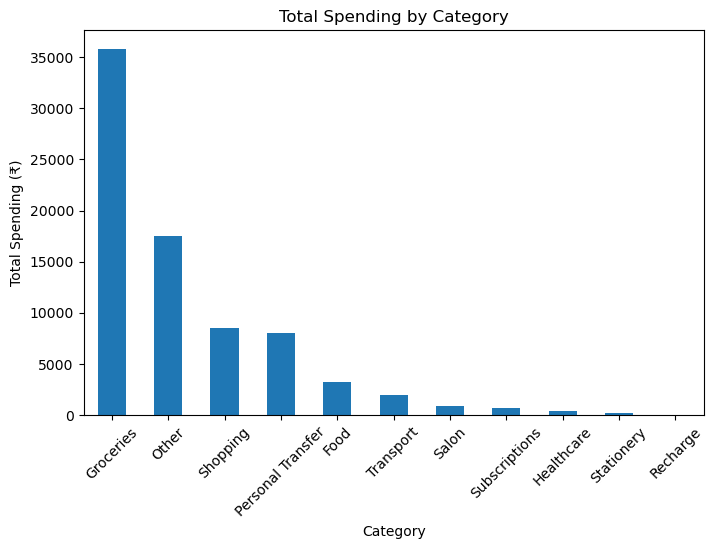

In [26]:
category_spend["Total_Spent"].plot(kind="bar",figsize=(8,5),title="Total Spending by Category")

plt.ylabel("Total Spending (₹)")
plt.xticks(rotation=45)
plt.show()

In [27]:
category_percent=(category_spend["Total_Spent"]/category_spend["Total_Spent"].sum())*100
category_percent.round(2)

Category
Groceries            46.31
Other                22.67
Shopping             11.04
Personal Transfer    10.36
Food                  4.17
Transport             2.52
Salon                 1.23
Subscriptions         0.85
Healthcare            0.53
Stationery            0.28
Recharge              0.05
Name: Total_Spent, dtype: float64

c. MERCHANT ANALYSIS

In [28]:
top_merchants=(df[df["Transaction_Type"]=="Paid"].groupby("Merchant")["Amount"].sum().sort_values(ascending=False).head(10))
top_merchants

Merchant
Blinkit                                   19731.55
ZEPTOMARKETPLACEPRIVATELIMITED            11438.35
Myntra                                     4829.00
ELWINEAPEN                                 2700.00
ElwinEapenM                                2301.00
VeeralChengappa                            2295.00
AjaiAntonyJoseph                           1698.00
NYKAA                                      1629.00
KARNATAKASTATEROADTRANSPORTCORPORATION     1542.00
GREENTRENDS                                1425.90
Name: Amount, dtype: float64

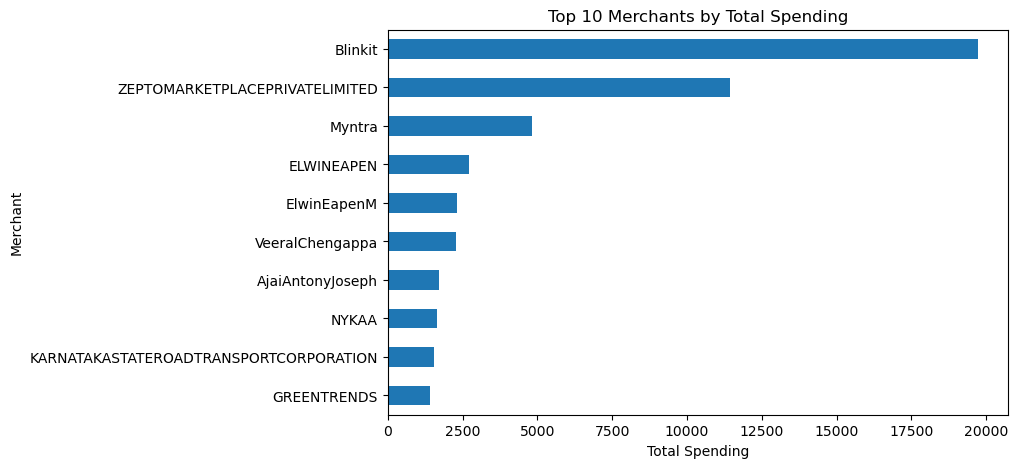

In [29]:
plt.figure(figsize=(8,5))

top_merchants.sort_values().plot(kind="barh")
plt.title("Top 10 Merchants by Total Spending")
plt.xlabel("Total Spending")
plt.show()

d. OTHER TRANSACTIONS

In [30]:
other_merchants=(df[df["Category"]=="Other"].groupby("Merchant").agg(Transactions=("Amount","size"),Total_Spent=("Amount","sum"),Average_Transaction=("Amount","mean")).sort_values("Transactions",ascending=False))

In [31]:
df[df["Category"]=="Other"][["Date","Merchant","Details","Amount"]].sort_values("Amount").head(200)

,Date,Merchant,Details,Amount
349,2026-04-08,PREPLACEDEDUCATIONPRIVATELIMITED,PaidtoPREPLACEDEDUCATIONPRIVATELIMITED,1.0
204,2026-02-21,Reshmaps,PaidtoReshmaps,4.0
79,2026-01-30,KA51AL6812,PaidtoKA51AL6812,6.0
346,2026-04-08,SADASHIVAIAH,PaidtoSADASHIVAIAH,7.0
102,2026-02-05,KavithaStores,PaidtoKavithaStores,10.0
...,...,...,...,...
503,2026-06-07,COORGAVENUESUPERSTORE,PaidtoCOORGAVENUESUPERSTORE,379.0
199,2026-02-19,SakaleshKg,PaidtoSakaleshKg,820.0
507,2026-06-25,SmartPartsOnline,PaidtoSmartPartsOnline,955.0
236,2026-02-28,DhillonThimmaiahCB,ReceivedfromDhillonThimmaiahCB,1000.0


In [32]:
other_trans=df[df["Category"]=="Other"][["Date","Merchant","Details","Amount"]]
other_trans.sort_values("Merchant")
other_trans.sort_values("Merchant").to_csv("other_transaction_sorted.csv",index=False)

In [33]:
personal_transactions=df[(df["Category"]=="Other")&(df["Merchant"].isin(["AamenaHussain","AfnaazMujawar","AjaiAntonyJoseph","DhillonThimmaiahCB","MRNishanthGowdaCM","FadiAmanSaifudeen","SwastikaSengupta","NamanM","ShereneMariaMathews","Vishal","SameerR","ShivamJPatel"]))][["Date","Merchant","Amount"]]

In [34]:
df.loc[personal_transactions.index, "Category"] = "Personal Transfer"

In [35]:
df["Category"].unique()

array(['Other', 'Groceries', 'Personal Transfer', 'Transport', 'Food',
       'Shopping', 'Healthcare', 'Subscriptions', 'Salon', 'Recharge',
       'Online Payment', 'Stationery'], dtype=object)

In [36]:
medical_other = df[
    (df["Category"] == "Other") &
    (df["Merchant"].str.contains("medical|pharmacy|pharma", case=False, na=False))
]

medical_other[["Date", "Merchant", "Amount"]]

,Date,Merchant,Amount
499,2026-06-05,AARNAMEDICALS,104.0


In [37]:
df.loc[medical_other.index, "Category"] = "Healthcare"

In [38]:
df.loc[medical_other.index, "Category"]

499    Healthcare
Name: Category, dtype: object

In [39]:
remaining_other = (
    df[df["Category"] == "Other"]
    .groupby("Merchant")
    .agg(
        Transactions=("Amount", "size"),
        Total_Spent=("Amount", "sum")
    )
    .sort_values("Transactions", ascending=False)
)

remaining_other.head(30)

,Transactions,Total_Spent
Merchant,,
SADASHIVA,3,180.0
RANJANCSSOSHANKAREGOWDAT,3,343.0
ErannaHm,2,121.0
GOVINDAR,2,135.0
NAGARAJA,2,170.0
ZABIULLAMM,2,112.0
PavanPavan,2,104.0
MANJUNATHAHN,2,135.0
Ganesh,2,550.0


In [40]:
df[
    (df["Category"] == "Other") &
    (df["Merchant"].str.contains("CONDIMENT", case=False, na=False))
][["Date", "Merchant", "Details", "Amount"]]

,Date,Merchant,Details,Amount
291,2026-03-17,NAVEEDCONDIMENTS,PaidtoNAVEEDCONDIMENTS,48.0


In [41]:
df.loc[(df["Category"]=="Other")&(df["Merchant"].str.contains("CONDIMENT",case=False, na=False)),"Category"]="Groceries"

In [42]:
df.loc[291, ["Merchant", "Amount", "Category"]]

Merchant    NAVEEDCONDIMENTS
Amount                  48.0
Category           Groceries
Name: 291, dtype: object

In [43]:
other_summary = (
    df["Category"]
    .value_counts()
    .to_frame("Transactions")
)

other_summary["Percentage"] = (
    other_summary["Transactions"] / len(df) * 100
).round(2)

other_summary

,Transactions,Percentage
Other,178,34.70
Personal Transfer,176,34.31
Groceries,97,18.91
Food,17,3.31
Transport,14,2.73
Shopping,9,1.75
Healthcare,7,1.36
Subscriptions,6,1.17
Salon,3,0.58
Stationery,3,0.58


In [44]:
df[df["Category"] == "Other"]["Amount"].describe()

count    178.00000
mean      87.19118
std      105.94890
min        1.00000
25%       50.00000
50%       58.00000
75%       79.00000
max      955.00000
Name: Amount, dtype: float64

In [45]:
other_above_100 = df[
    (df["Category"] == "Other") &
    (df["Amount"] > 100)
][["Date", "Merchant", "Details", "Amount"]]

other_above_100.sort_values("Amount", ascending=False)

,Date,Merchant,Details,Amount
507,2026-06-25,SmartPartsOnline,PaidtoSmartPartsOnline,955.0
199,2026-02-19,SakaleshKg,PaidtoSakaleshKg,820.0
503,2026-06-07,COORGAVENUESUPERSTORE,PaidtoCOORGAVENUESUPERSTORE,379.0
197,2026-02-19,Ganesh,PaidtoGanesh,350.0
181,2026-02-18,MAHANTHESH R W00616,PaidtoMAHANTHESH R W00616,330.0
202,2026-02-19,SriKrishnaCafe,PaidtoSriKrishnaCafe,273.0
158,2026-02-16,KHUSHICHATSCENTER,PaidtoKHUSHICHATSCENTER,260.0
430,2026-05-05,LALRINOMI NGAMLAI,PaidtoLALRINOMI NGAMLAI,250.0
176,2026-02-18,FAISALNOWSHAD,PaidtoFAISALNOWSHAD,240.0
206,2026-02-23,HARISHKUMARDR,PaidtoHARISHKUMARDR,240.0


In [47]:
other_summary = (
    df["Category"]
    .value_counts()
    .to_frame("Transactions")
)

other_summary["Percentage"] = (
    other_summary["Transactions"] / len(df) * 100
).round(2)

other_summary

,Transactions,Percentage
Personal Transfer,177,34.50
Other,154,30.02
Groceries,102,19.88
Food,24,4.68
Transport,18,3.51
Shopping,15,2.92
Healthcare,7,1.36
Subscriptions,7,1.36
Salon,3,0.58
Stationery,3,0.58


In [48]:
remaining_other = df[df["Category"] == "Other"][
    ["Date", "Merchant", "Details", "Amount"]
].sort_values("Date")

remaining_other.to_csv(
    "remaining_other_transactions.csv",
    index=False
)

In [49]:
other_spending = df[df["Category"] == "Other"]["Amount"].sum()

total_spending = df[df["Transaction_Type"] == "Paid"]["Amount"].sum()

print("Other spending: ₹", round(other_spending, 2))
print("Other spending %:", round(other_spending / total_spending * 100, 2))

Other spending: ₹ 11885.03
Other spending %: 15.36


In [50]:
other_uber_range = df[
    (df["Category"] == "Other") &
    (df["Amount"].between(47, 80))
]

print("Transactions:", len(other_uber_range))
print("Total spent: ₹", round(other_uber_range["Amount"].sum(), 2))
print("Share of Other transactions:",
      round(len(other_uber_range) / len(df[df["Category"] == "Other"]) * 100, 2))
print("Share of Other spending:",
      round(other_uber_range["Amount"].sum() /
            df[df["Category"] == "Other"]["Amount"].sum() * 100, 2))

Transactions: 99
Total spent: ₹ 5825.58
Share of Other transactions: 64.29
Share of Other spending: 49.02


In [51]:
other_ride_range = df[
    (df["Category"] == "Other") &
    (df["Amount"].between(47, 80))
].copy()

other_ride_range[["Date", "Time", "Merchant", "Amount"]].head(20)

,Date,Time,Merchant,Amount
2,2026-01-05,1900-01-01 07:29:00,PARASHURAMA,56.15
19,2026-01-12,1900-01-01 07:27:00,GOVINDAR,68.00
21,2026-01-12,1900-01-01 09:46:00,SADASHIVA,60.00
24,2026-01-14,1900-01-01 07:49:00,RANJANCSSOSHANKAREGOWDAT,66.00
33,2026-01-16,1900-01-01 08:11:00,RIDAFATHIMAKHANUM,62.00
46,2026-01-22,1900-01-01 08:12:00,Saniya Sultana,56.00
62,2026-01-28,1900-01-01 10:27:00,MRCHENNEGOWDA KC,59.00
71,2026-01-29,1900-01-01 08:00:00,KISHANKUMAR,56.00
77,2026-01-30,1900-01-01 08:01:00,ErannaHm,56.00
86,2026-01-31,1900-01-01 14:05:00,VENKATESHG,70.00


A substantial proportion of otherwise uncategorised transactions occurred within the ₹47–₹80 range, consistent with the user's typical ride-hailing expenditure. However, these transactions were retained under Other because the available merchant information did not reliably identify them as transport expenses.

In [52]:
len(df)

513

In [53]:
df["Transaction_Type"].value_counts()

Paid        370
Received    143
Name: Transaction_Type, dtype: int64

In [54]:
df.duplicated().sum()

0

In [55]:
df.groupby("Month").size()

Month
April        86
February    151
January      87
June         21
March        85
May          83
dtype: int64

In [56]:
likely_transport=df[(df["Category"]=="Other")&(df["Merchant"].str.match(r"KA\d{2}",na=False))]
likely_transport

,Date,Time,Details,Amount,UPI_ID,Bank,Transaction_Type,Merchant,Month,Month_Num,Day,Year,Day_Type,Hour,Category
9,2026-01-08,1900-01-01 11:38:00,PaidtoKA01AR2969,15.0,600812237069,PaidbyStateBankofIndia7202,Paid,KA01AR2969,January,1,Thursday,2026,Weekday,11,Other
26,2026-01-14,1900-01-01 11:07:00,PaidtoKA01AR2872,15.0,601418439014,PaidbyStateBankofIndia7202,Paid,KA01AR2872,January,1,Wednesday,2026,Weekday,11,Other
79,2026-01-30,1900-01-01 12:50:00,PaidtoKA51AL6812,6.0,603096414572,PaidbyStateBankofIndia7202,Paid,KA51AL6812,January,1,Friday,2026,Weekday,12,Other
311,2026-03-26,1900-01-01 11:17:00,PaidtoKA01AR2824,15.0,608584665222,PaidbyStateBankofIndia7202,Paid,KA01AR2824,March,3,Thursday,2026,Weekday,11,Other
439,2026-05-07,1900-01-01 15:34:00,PaidtoKA01AR2809,15.0,612775442856,PaidbyStateBankofIndia7202,Paid,KA01AR2809,May,5,Thursday,2026,Weekday,15,Other


In [57]:
len(likely_transport)

5

In [58]:
likely_transport["Amount"].sum()
likely_transport["Amount"].describe()

count     5.000000
mean     13.200000
std       4.024922
min       6.000000
25%      15.000000
50%      15.000000
75%      15.000000
max      15.000000
Name: Amount, dtype: float64

In [59]:
df.loc[likely_transport.index,"Category"]="Transport"

In [60]:
df.loc[likely_transport.index,"Category"]

9      Transport
26     Transport
79     Transport
311    Transport
439    Transport
Name: Category, dtype: object

7. MONTHLY SPENDING TREND

In [61]:
monthly_spending=df[df["Transaction_Type"]=="Paid"].groupby("Month")["Amount"].sum()
month_order=["January","February","March","April","May","June"]
monthly_spending= monthly_spending.reindex(month_order)
monthly_spending

Month
January     14027.44
February    22120.71
March       10446.02
April        7140.82
May         13462.00
June        10172.00
Name: Amount, dtype: float64

In [62]:
monthly_spending.round(2)

Month
January     14027.44
February    22120.71
March       10446.02
April        7140.82
May         13462.00
June        10172.00
Name: Amount, dtype: float64

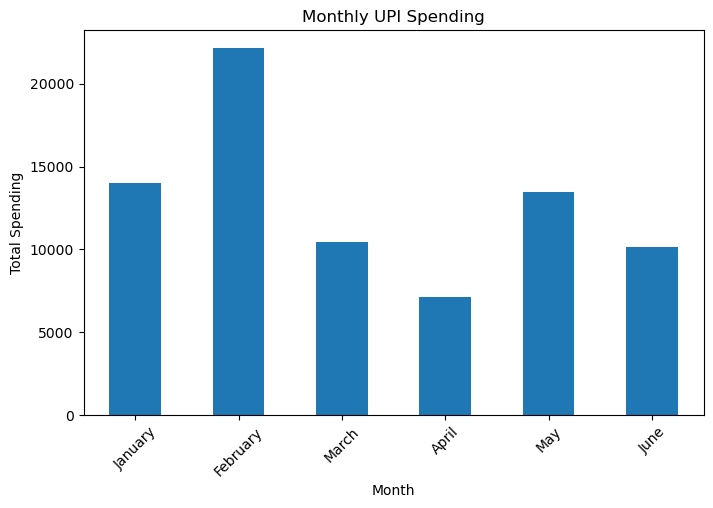

In [63]:
monthly_spending.plot(kind="bar",figsize=(8,5),title="Monthly UPI Spending")
plt.xlabel("Month")
plt.ylabel("Total Spending")
plt.xticks(rotation=45)
plt.show()

In [64]:
highest_month=monthly_spending.idxmax()
highest_amount=monthly_spending.max()
lowest_month=monthly_spending.idxmin()
lowest_amount=monthly_spending.min()
print(f"Highest Spending: {highest_month}= ₹{highest_amount}")
print(f"Lowest Spending: {lowest_month}= ₹{lowest_amount}")

Highest Spending: February= ₹22120.71
Lowest Spending: April= ₹7140.82


8. TRANSACTION BEHAVIOUR

In [65]:
transactions_by_month = (
    df[df["Transaction_Type"] == "Paid"]
    .groupby("Month")
    .size()
)

transactions_by_month

Month
April        61
February    107
January      61
June         14
March        68
May          59
dtype: int64

In [66]:
transactions_by_month = transactions_by_month.reindex(month_order)

transactions_by_month

Month
January      61
February    107
March        68
April        61
May          59
June         14
dtype: int64

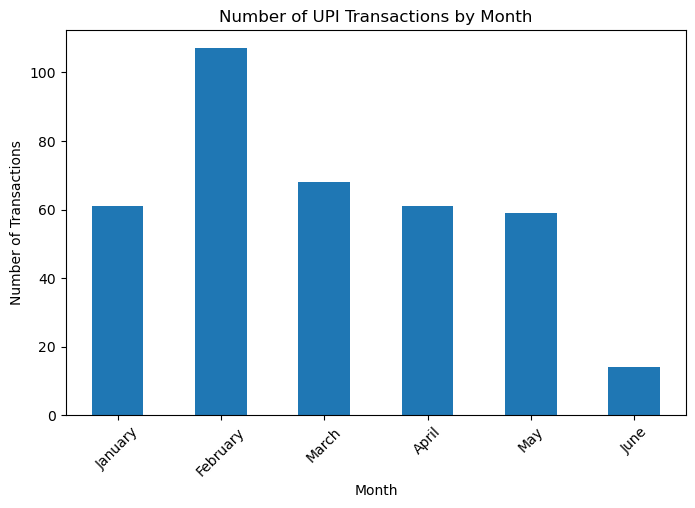

In [67]:
transactions_by_month.plot(kind="bar",figsize=(8,5),title="Number of UPI Transactions by Month"
)

plt.xlabel("Month")
plt.ylabel("Number of Transactions")
plt.xticks(rotation=45)
plt.show()

In [68]:
average_transaction = (
    df[df["Transaction_Type"] == "Paid"]
    .groupby("Month")["Amount"]
    .mean()
)

average_transaction = average_transaction.reindex(month_order)
average_transaction.round(2)

Month
January     229.96
February    206.74
March       153.62
April       117.06
May         228.17
June        726.57
Name: Amount, dtype: float64

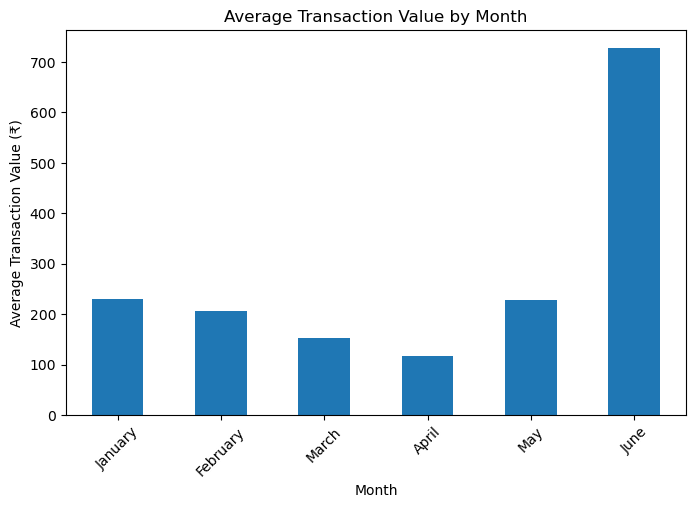

In [69]:
average_transaction.plot(
    kind="bar",
    figsize=(8, 5),
    title="Average Transaction Value by Month"
)

plt.xlabel("Month")
plt.ylabel("Average Transaction Value (₹)")
plt.xticks(rotation=45)
plt.show()

In [70]:
weekday_weekend = (
    df[df["Transaction_Type"] == "Paid"]
    .groupby("Day_Type")["Amount"]
    .sum()
)

weekday_weekend

Day_Type
Weekday    60123.92
Weekend    17245.07
Name: Amount, dtype: float64

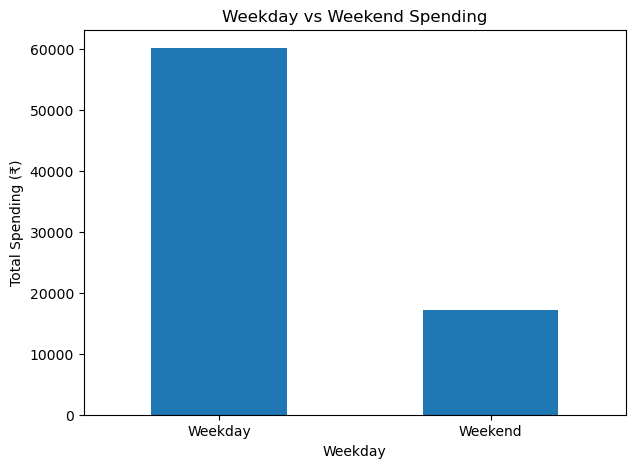

In [71]:
weekday_weekend.plot(
    kind="bar",
    figsize=(7, 5),
    title="Weekday vs Weekend Spending"
)

plt.xlabel("Weekday")
plt.ylabel("Total Spending (₹)")
plt.xticks(rotation=0)
plt.show()

In [72]:
largest_payments = (
    df[df["Transaction_Type"] == "Paid"]
    .nlargest(10, "Amount")
    [["Date", "Merchant", "Category", "Amount"]]
)

largest_payments

,Date,Merchant,Category,Amount
505,2026-06-18,Myntra,Shopping,2277.0
445,2026-05-08,ELWINEAPEN,Personal Transfer,2044.0
488,2026-05-27,Blinkit,Groceries,1819.0
510,2026-06-25,Myntra,Shopping,1739.0
145,2026-02-14,NYKAA,Shopping,1629.0
191,2026-02-19,KARNATAKASTATEROADTRANSPORTCORPORATION,Transport,1542.0
56,2026-01-26,ZEPTOMARKETPLACEPRIVATELIMITED,Groceries,1524.0
464,2026-05-12,AjaiAntonyJoseph,Personal Transfer,1500.0
44,2026-01-21,Blinkit,Groceries,1304.0
18,2026-01-11,ElwinEapenM,Personal Transfer,1300.0


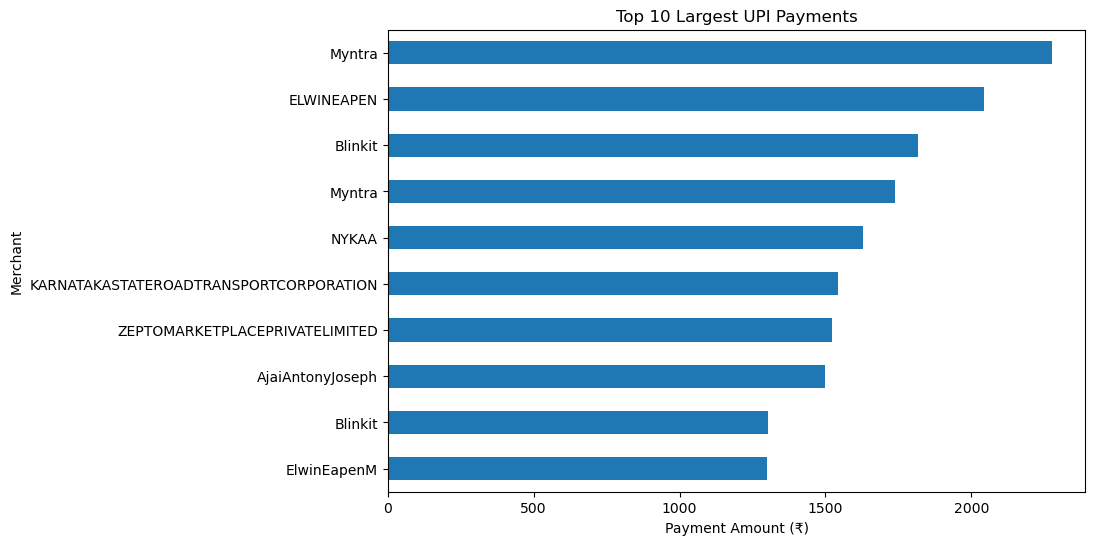

In [73]:
largest_payments_sorted = largest_payments.sort_values("Amount")

largest_payments_sorted.plot(
    x="Merchant",
    y="Amount",
    kind="barh",
    figsize=(9, 6),
    title="Top 10 Largest UPI Payments",
    legend=False
)

plt.xlabel("Payment Amount (₹)")
plt.ylabel("Merchant")
plt.show()

In [74]:
paid = df[df["Transaction_Type"]=="Paid"].copy()

paid_sorted = paid.sort_values("Amount", ascending=False)

top_10_percent_count = int(len(paid_sorted) * 0.10)

top_10_percent_spending = paid_sorted.head(top_10_percent_count)["Amount"].sum()

total_spending = paid_sorted["Amount"].sum()

print("Top 10% transaction count:", top_10_percent_count)
print("Top 10% spending: ₹", round(top_10_percent_spending, 2))
print(
    "Share of total spending:",
    round(top_10_percent_spending / total_spending * 100, 2),
    "%"
)

Top 10% transaction count: 37
Top 10% spending: ₹ 39955.07
Share of total spending: 51.64 %


In [75]:
top_10_percent = paid_sorted.head(top_10_percent_count)

top_10_percent[
    ["Date", "Merchant", "Category", "Amount"]
]

,Date,Merchant,Category,Amount
505,2026-06-18,Myntra,Shopping,2277.00
445,2026-05-08,ELWINEAPEN,Personal Transfer,2044.00
488,2026-05-27,Blinkit,Groceries,1819.00
510,2026-06-25,Myntra,Shopping,1739.00
145,2026-02-14,NYKAA,Shopping,1629.00
191,2026-02-19,KARNATAKASTATEROADTRANSPORTCORPORATION,Transport,1542.00
56,2026-01-26,ZEPTOMARKETPLACEPRIVATELIMITED,Groceries,1524.00
464,2026-05-12,AjaiAntonyJoseph,Personal Transfer,1500.00
44,2026-01-21,Blinkit,Groceries,1304.00
18,2026-01-11,ElwinEapenM,Personal Transfer,1300.00


In [76]:
top10_category = (
    top_10_percent
    .groupby("Category")["Amount"]
    .agg(["count", "sum"])
    .sort_values("sum", ascending=False)
)

top10_category

,count,sum
Category,,
Groceries,21,20632.07
Shopping,6,8001.00
Personal Transfer,6,7644.00
Transport,1,1542.00
Other,1,820.00
Salon,1,700.00
Food,1,616.00


SPENDING CONCENTRATION
- The largest 10% of paid transactions (37 transactions) accounted for 51.64% of total spending. 
- Groceries were the largest contributor, accounting for 21 of these transactions and ₹20,632.07 (51.7%) of their combined value.
- Groceries, shopping and personal transfers together represented approximately 90.8% of spending within the top 10% of transactions.

9. KEY INSIGHTS

10. LIMITATIONS